In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/helpdesk_customer_tickets.csv")   # change the filename

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:\n", df.isna().sum())

# Show one row in full
print("\nSample row:\n", df.iloc[0])

# Show value counts for every short-text column (the label-like ones)
for col in df.columns:
    if df[col].dtype == "object" and df[col].nunique() < 30:
        print(f"\n--- {col} ---")
        print(df[col].value_counts(dropna=False))

Shape: (600, 18)

Columns: ['id', 'subject', 'body', 'answer', 'type', 'queue', 'priority', 'language', 'business_type', 'tag_1', 'tag_2', 'tag_3', 'tag_4', 'tag_5', 'tag_6', 'tag_7', 'tag_8', 'tag_9']

Missing values:
 id                 0
subject            1
body               0
answer             0
type               0
queue              0
priority           0
language           0
business_type      0
tag_1              0
tag_2              0
tag_3              0
tag_4              0
tag_5            168
tag_6            427
tag_7            544
tag_8            591
tag_9            600
dtype: int64

Sample row:
 id                                                              36
subject          Anfrage zu den Spezifikationen und Anpassungso...
body             Sehr geehrtes Support-Team des Tech Online Sto...
answer           Sehr geehrter <name>,\n\nvielen Dank für Ihr I...
type                                                       Request
queue                                   

In [2]:
print("Language:\n", df["language"].value_counts(), "\n")

en = df[df["language"] == "en"].copy()
print("English rows:", len(en), "\n")

print("Queue (English):\n", en["queue"].value_counts(), "\n")
print("Priority (English):\n", en["priority"].value_counts(), "\n")
print("Type (English):\n", en["type"].value_counts(), "\n")

# Tags carry useful extra labels
tags = pd.concat([en[f"tag_{i}"] for i in range(1, 10)]).dropna()
print("Top tags (English):\n", tags.value_counts().head(25), "\n")

print("Duplicate bodies:", en["body"].duplicated().sum())
print("Missing subject:", en["subject"].isna().sum())

Language:
 language
en    163
de    152
es    133
pt     81
fr     71
Name: count, dtype: int64 

English rows: 163 

Queue (English):
 queue
Technical Support                  57
Product Support                    32
Customer Service                   22
IT Support                         19
Billing and Payments               12
Returns and Exchanges              11
Human Resources                     4
Service Outages and Maintenance     4
Sales and Pre-Sales                 2
Name: count, dtype: int64 

Priority (English):
 priority
high      73
medium    53
low       37
Name: count, dtype: int64 

Type (English):
 type
Incident    75
Problem     41
Request     32
Change      15
Name: count, dtype: int64 

Top tags (English):
 Technical Support        144
Problem Resolution       140
Product Support           85
Urgent Issue              71
Hardware Failure          55
Software Bug              54
IT Support                32
Customer Service          28
Service Disruption        24

In [3]:
for q in ["Customer Service", "Product Support"]:
    print("=====", q)
    for _, r in en[en["queue"] == q].sample(6, random_state=2).iterrows():
        print("-", r["subject"], "|", str(r["body"])[:250], "\n")

===== Customer Service
- Frequent audio dropouts during video conferences | Dear IT services support team, I am experiencing frequent audio dropouts during my video conferences despite having stable network conditions. This issue persists specifically with Zoom version 5.11.0. My account number is <acc_num>. Could you please 

- Issue Changing Status in Jira Software Project | Dear Customer Support Team, 

I am unable to change the issue status in my Jira Software 8.20 project. It seems to require an administrative viewing configuration adjustment. Please assist me in resolving this issue at your earliest convenience.

Tha 

- Assistance Required for Persistent Paper Jam Issues with Canon Printer | Dear Customer Support,

I am writing to report persistent paper jam issues with my Canon PIXMA MG3620 printer. The problem occurs during light checkout documentation printing. I have ensured that the paper is not overloaded, and I have also checked f 

- Inquiry about Dell XPS 13 9310 Availa

In [4]:
import re, random
random.seed(42)

en = df[df["language"] == "en"].copy()

QUEUE_MAP = {
    "Technical Support": "Technical Support",
    "IT Support": "Technical Support",
    "Service Outages and Maintenance": "Technical Support",
    "Product Support": "Technical Support",
    "Customer Service": "Technical Support",
    "Billing and Payments": "Payment Issue",
    "Returns and Exchanges": "Refund Request",
}
en = en[en["queue"].isin(QUEUE_MAP)].copy()
en["category"] = en["queue"].map(QUEUE_MAP)

# Keyword overrides for the two noisy queues
sales_kw = r"availability|in stock|delivery|pricing|price|quote|purchase|order"
inquiry_kw = r"compatib|inquiry|recommend|information about|upgrade"

text = (en["subject"].fillna("") + " " + en["body"]).str.lower()
noisy = en["queue"].isin(["Product Support", "Customer Service"])

en["needs_review"] = False
m_sales = noisy & text.str.contains(sales_kw)
m_inq = noisy & ~m_sales & text.str.contains(inquiry_kw)
en.loc[m_sales, ["category", "needs_review"]] = ["Sales Inquiry", True]
en.loc[m_inq, ["category", "needs_review"]] = ["General Inquiry", True]
# Billing/returns rows also get a quick look
en.loc[en["queue"].isin(["Billing and Payments", "Returns and Exchanges"]), "needs_review"] = True

# Replace placeholders with realistic values
names = ["Alex", "Priya", "John", "Sara", "Ravi", "Maria", "David", "Anita"]
def fill(t):
    t = re.sub(r"<name>", lambda m: random.choice(names), str(t))
    t = re.sub(r"<acc_num>", lambda m: str(random.randint(100000, 999999)), t)
    return t

out = pd.DataFrame({
    "email_id": ["K" + str(i).zfill(4) for i in range(len(en))],
    "subject": en["subject"].fillna("No subject").map(fill).values,
    "body": en["body"].map(fill).values,
    "category": en["category"].values,
    "priority": en["priority"].str.capitalize().values,
    "source": "kaggle",
    "needs_review": en["needs_review"].values,
})

print(out["category"].value_counts())
print("\nRows to review:", out["needs_review"].sum())
out.to_csv("../data/raw/kaggle_en_mapped.csv", index=False)

category
Technical Support    119
Payment Issue         12
Refund Request        11
Sales Inquiry          9
General Inquiry        6
Name: count, dtype: int64

Rows to review: 38


In [5]:
pd.set_option("display.max_colwidth", 160)
print(out[out["needs_review"]][["email_id", "subject", "category"]].to_string())

    email_id                                                             subject         category
0      K0000                                                          No subject   Refund Request
8      K0008                 Return Request: Defective Samsung QN90A HDR Feature   Refund Request
13     K0013                           Repeated Screen Flickering Issue Reported    Sales Inquiry
16     K0016                                         Request for PyCharm Upgrade  General Inquiry
24     K0024                       Faulty Canon PIXMA MG3620 Wireless Connection   Refund Request
39     K0039                                              Cannot Process Payment    Payment Issue
41     K0041                                               Compatibility Inquiry    Sales Inquiry
45     K0045              Overcharge on yearly Microsoft Office 365 subscription    Payment Issue
49     K0049                      Inquiry on Surface Pro 7 Monitor Compatibility  General Inquiry
51     K0051        

In [6]:
check = ["K0000", "K0024", "K0080", "K0117", "K0126", "K0139", "K0143"]
for _, r in out[out["email_id"].isin(check)].iterrows():
    print(r["email_id"], "|", r["category"], "|", r["subject"])
    print(r["body"][:350], "\n")

K0000 | Refund Request | No subject
Dear Tech Online Store Customer Support,

I am writing to report wireless connection issues with my recently purchased Canon PIXMA MG3620 printer within the return eligibility period. Despite multiple attempts at troubleshooting, the printer fails to connect to my home network reliably, making it difficult to use. I am seeking assistance in resolvi 

K0024 | Refund Request | Faulty Canon PIXMA MG3620 Wireless Connection
Dear Tech Online Store Support,

I recently purchased a Canon PIXMA MG3620 printer from your store, but unfortunately, I have encountered an issue with its wireless connection. The printer frequently disconnects from the Wi-Fi, making it impossible to use. I have tried multiple troubleshooting steps but to no avail. Could you please assist me in pr 

K0080 | Sales Inquiry | Request to Change Delivery Address
Dear Customer Support,

I hope this message finds you well. I recently placed an order for a Dell XPS 13 9310 laptop. Unfortunat

In [7]:
fixes = {
    "K0013": "Technical Support", "K0062": "Technical Support",
    "K0090": "Technical Support", "K0093": "Technical Support",
    "K0134": "Technical Support", "K0135": "Technical Support",
    "K0041": "General Inquiry",   "K0095": "Refund Request",
    # add your decisions from the body check, for example:
    # "K0117": "Technical Support", "K0126": "Technical Support",
    # "K0139": "General Inquiry",   "K0143": "Technical Support",
}
for eid, cat in fixes.items():
    out.loc[out["email_id"] == eid, "category"] = cat

out["needs_review"] = False
print(out["category"].value_counts())
out.to_csv("../data/raw/kaggle_en_clean.csv", index=False)

category
Technical Support    125
Refund Request        12
Payment Issue         12
General Inquiry        6
Sales Inquiry          2
Name: count, dtype: int64


In [8]:
print(out.loc[out["email_id"] == "K0024", "body"].values[0])

Dear Tech Online Store Support,

I recently purchased a Canon PIXMA MG3620 printer from your store, but unfortunately, I have encountered an issue with its wireless connection. The printer frequently disconnects from the Wi-Fi, making it impossible to use. I have tried multiple troubleshooting steps but to no avail. Could you please assist me in processing a replacement or exchange unit?

My account number is 325772. You can contact me on <tel_num> if further information is needed.

Thank you for your assistance.

Best regards,
John


In [9]:
fixes2 = {
    "K0000": "Technical Support",
    "K0024": "Technical Support",   # change to Refund Request if the body asks for a return
    "K0080": "General Inquiry",
    "K0117": "Technical Support",
    "K0126": "Refund Request",
    "K0139": "General Inquiry",
    "K0143": "Technical Support",
}
for eid, cat in fixes2.items():
    out.loc[out["email_id"] == eid, "category"] = cat

print(out["category"].value_counts())
out.to_csv("../data/raw/kaggle_en_clean.csv", index=False)

category
Technical Support    129
Payment Issue         10
Refund Request         9
General Inquiry        8
Sales Inquiry          1
Name: count, dtype: int64


In [10]:
import pandas as pd

d = pd.read_csv("../data/synthetic/payment_1.csv")

print("Rows:", len(d))
print("Columns:", d.columns.tolist())
print("\nPriority:\n", d["priority"].value_counts())

# Length variety (words per email)
d["words"] = d["body"].str.split().str.len()
print("\nLength:\n", d["words"].describe())

# Repeated openings
print("\nMost common openings:\n", d["body"].str[:20].value_counts().head(8))

# Duplicates
print("\nDuplicate bodies:", d["body"].duplicated().sum())

# Read a random sample
pd.set_option("display.max_colwidth", 300)
print(d.sample(6, random_state=1)[["subject", "body", "priority"]].to_string())

Rows: 40
Columns: ['subject', 'body', 'priority']

Priority:
 priority
Medium    19
High      16
Low        5
Name: count, dtype: int64

Length:
 count     40.00000
mean      53.00000
std       33.37126
min       12.00000
25%       24.75000
50%       46.50000
75%       72.50000
max      129.00000
Name: words, dtype: float64

Most common openings:
 body
Hi, I was charged tw    1
hello, i ordered a b    1
Tried to recharge my    1
Dear Support Team, I    1
Hi team, I cancelled    1
Hello, my order #UL-    1
order 55291 - applie    1
Good afternoon, I am    1
Name: count, dtype: int64

Duplicate bodies: 0
                                         subject                                                                                                                                                                                                                                                                                                                                                      

In [11]:
kw = ["twice|two times|2x|double", "pending|no order|not confirmed", "declin|3d secure|failed",
      "wrong amount|overcharg|incorrect", "invoice|gst|receipt", "cancel", "emi|offer|coupon|discount"]
for k in kw:
    print(k, "->", d["body"].str.lower().str.contains(k).sum())

twice|two times|2x|double -> 4
pending|no order|not confirmed -> 2
declin|3d secure|failed -> 8
wrong amount|overcharg|incorrect -> 1
invoice|gst|receipt -> 4
cancel -> 3
emi|offer|coupon|discount -> 5


In [12]:
import pandas as pd

d = pd.read_csv("../data/synthetic/refund_1.csv")

print("Rows:", len(d))
print("Columns:", d.columns.tolist())
print("\nPriority:\n", d["priority"].value_counts())

# Length variety (words per email)
d["words"] = d["body"].str.split().str.len()
print("\nLength:\n", d["words"].describe())

# Repeated openings
print("\nMost common openings:\n", d["body"].str[:20].value_counts().head(8))

# Duplicates
print("\nDuplicate bodies:", d["body"].duplicated().sum())

# Read a random sample
pd.set_option("display.max_colwidth", 300)
print(d.sample(6, random_state=1)[["subject", "body", "priority"]].to_string())

Rows: 40
Columns: ['subject', 'body', 'priority']

Priority:
 priority
Medium    31
High       6
Low        3
Name: count, dtype: int64

Length:
 count     40.000000
mean      52.125000
std       26.798572
min       22.000000
25%       36.000000
50%       44.000000
75%       60.250000
max      119.000000
Name: words, dtype: float64

Most common openings:
 body
Returned the kurta s    1
Hi, order GC-558213     1
Dear Sir or Madam, I    1
hey, i cancelled my     1
My EUR 220 security     1
Left earbud on my So    1
Bought the winter pa    1
Hello Circuit Hub su    1
Name: count, dtype: int64

Duplicate bodies: 0
                                                        subject                                                                                                                                                                                                                                                                                                                               

In [13]:
kw = ["defect|faulty|damaged|flicker|broken", "cancel", "wrong item|incorrect item",
      "not received|nothing|still waiting|overdue", "store credit|voucher", "partial|part of"]
for k in kw:
    print(k, "->", d["body"].str.lower().str.contains(k).sum())

defect|faulty|damaged|flicker|broken -> 1
cancel -> 17
wrong item|incorrect item -> 0
not received|nothing|still waiting|overdue -> 6
store credit|voucher -> 3
partial|part of -> 2


In [14]:
d = pd.read_csv("../data/synthetic/account_1.csv")

print("Rows:", len(d))
print("Columns:", d.columns.tolist())
print("\nPriority:\n", d["priority"].value_counts())

# Length variety (words per email)
d["words"] = d["body"].str.split().str.len()
print("\nLength:\n", d["words"].describe())

# Repeated openings
print("\nMost common openings:\n", d["body"].str[:20].value_counts().head(8))

# Duplicates
print("\nDuplicate bodies:", d["body"].duplicated().sum())

# Read a random sample
pd.set_option("display.max_colwidth", 300)
print(d.sample(6, random_state=1)[["subject", "body", "priority"]].to_string())

Rows: 40
Columns: ['subject', 'body', 'priority']

Priority:
 priority
Medium    18
Low       12
High      10
Name: count, dtype: int64

Length:
 count     40.000000
mean      49.200000
std       31.360763
min       14.000000
25%       25.750000
50%       41.000000
75%       55.500000
max      115.000000
Name: words, dtype: float64

Most common openings:
 body
The password reset l    1
otp is not coming on    1
My Chase app locked     1
Someone changed my p    1
Hi, I recently switc    1
Hello, how do I perm    1
Got a new phone and     1
Hello, I created a P    1
Name: count, dtype: int64

Duplicate bodies: 0
                                 subject                                                                                                                                                                                                                                                                 body priority
2        URGENT: locked out of Chase app                               

In [15]:
print(d.isna().sum())
print(d.iloc[29])

subject     0
body        0
priority    0
words       0
dtype: int64
subject                                                                                                                                                                                                    Update my surname on profile
body        I got married in September and need to update my last name on my Airbnb profile to match my new passport before my December trip. The edit option for names seems to be disabled for me. Can you help? Regards, Divya Raman
priority                                                                                                                                                                                                                            Low
words                                                                                                                                                                                                                                42
Nam

In [16]:
d = pd.read_csv("../data/synthetic/sales_1.csv")

print("Rows:", len(d))
print("Columns:", d.columns.tolist())
print("\nPriority:\n", d["priority"].value_counts())

# Length variety (words per email)
d["words"] = d["body"].str.split().str.len()
print("\nLength:\n", d["words"].describe())

# Repeated openings
print("\nMost common openings:\n", d["body"].str[:20].value_counts().head(8))

# Duplicates
print("\nDuplicate bodies:", d["body"].duplicated().sum())

# Read a random sample
pd.set_option("display.max_colwidth", 300)
print(d.sample(6, random_state=1)[["subject", "body", "priority"]].to_string())

Rows: 40
Columns: ['subject', 'body', 'priority']

Priority:
 priority
Low       25
Medium    13
High       2
Name: count, dtype: int64

Length:
 count     40.000000
mean      49.650000
std       31.017406
min       13.000000
25%       23.250000
50%       44.000000
75%       56.000000
max      113.000000
Name: words, dtype: float64

Most common openings:
 body
Hope this email find    2
Hi, what does your P    1
Dear Sir/Madam, I ha    1
can we get a 14 day     1
Hello, I'm planning     1
Dear Team, I am the     1
is the oslo 3 seater    1
Hello, I am the Head    1
Name: count, dtype: int64

Duplicate bodies: 0
                                                       subject                                                                                                                                                                                                                                                                                                                                

In [17]:
d = pd.read_csv("../data/synthetic/complaint_1.csv")

print("Rows:", len(d))
print("Columns:", d.columns.tolist())
print("\nPriority:\n", d["priority"].value_counts())

# Length variety (words per email)
d["words"] = d["body"].str.split().str.len()
print("\nLength:\n", d["words"].describe())

# Repeated openings
print("\nMost common openings:\n", d["body"].str[:20].value_counts().head(8))

# Duplicates
print("\nDuplicate bodies:", d["body"].duplicated().sum())

# Read a random sample
pd.set_option("display.max_colwidth", 300)
print(d.sample(6, random_state=1)[["subject", "body", "priority"]].to_string())

Rows: 40
Columns: ['subject', 'body', 'priority']

Priority:
 priority
Medium    24
High      11
Low        5
Name: count, dtype: int64

Length:
 count     40.000000
mean      68.850000
std       38.804275
min       20.000000
25%       34.250000
50%       64.000000
75%       86.750000
max      166.000000
Name: words, dtype: float64

Most common openings:
 body
The gate agent on Ae    1
Dear Customer Care,     1
This is now my third    1
u advertised FLY ANY    1
Seat 14C had a stain    1
75 minutes for TWO d    1
Good afternoon, I di    1
we ate at Spice Rout    1
Name: count, dtype: int64

Duplicate bodies: 0
                                subject                                                                                                                                                                                                                                                                                                                                                       

In [18]:
d = pd.read_csv("../data/synthetic/job_1.csv")

print("Rows:", len(d))
print("Columns:", d.columns.tolist())
print("\nPriority:\n", d["priority"].value_counts())

# Length variety (words per email)
d["words"] = d["body"].str.split().str.len()
print("\nLength:\n", d["words"].describe())

# Repeated openings
print("\nMost common openings:\n", d["body"].str[:20].value_counts().head(8))

# Duplicates
print("\nDuplicate bodies:", d["body"].duplicated().sum())

# Read a random sample
pd.set_option("display.max_colwidth", 300)
print(d.sample(6, random_state=1)[["subject", "body", "priority"]].to_string())

Rows: 40
Columns: ['subject', 'body', 'priority']

Priority:
 priority
Low       33
Medium     6
High       1
Name: count, dtype: int64

Length:
 count     40.000000
mean      58.200000
std       32.683564
min       17.000000
25%       27.750000
50%       56.500000
75%       70.250000
max      130.000000
Name: words, dtype: float64

Most common openings:
 body
Hello Team, I'd like    1
Hi, please find my C    1
Dear Hiring Manager,    1
hello sir/madam, i s    1
Hi, do you take summ    1
Hello! I'm a final-y    1
Dear Sir or Madam, I    1
Hey, I'm doing my B.    1
Name: count, dtype: int64

Duplicate bodies: 0
                                                                  subject                                                                                                                                                                                                                                                                                                                     

In [19]:
d = pd.read_csv("../data/synthetic/general_1.csv")

print("Rows:", len(d))
print("Columns:", d.columns.tolist())
print("\nPriority:\n", d["priority"].value_counts())

# Length variety (words per email)
d["words"] = d["body"].str.split().str.len()
print("\nLength:\n", d["words"].describe())

# Repeated openings
print("\nMost common openings:\n", d["body"].str[:20].value_counts().head(8))

# Duplicates
print("\nDuplicate bodies:", d["body"].duplicated().sum())

# Read a random sample
pd.set_option("display.max_colwidth", 300)
print(d.sample(6, random_state=1)[["subject", "body", "priority"]].to_string())

Rows: 40
Columns: ['subject', 'body', 'priority']

Priority:
 priority
Low       31
Medium     8
High       1
Name: count, dtype: int64

Length:
 count     40.000000
mean      49.500000
std       30.907637
min       14.000000
25%       21.000000
50%       41.500000
75%       58.000000
max      119.000000
Name: words, dtype: float64

Most common openings:
 body
Is the Madurai Distr     1
Dear Sir/Madam,\nCoul    1
Hello,\nWe are visiti    1
hi, what time does t     1
Where exactly is you     1
Dear Admissions Offi     1
Hi there,\nI came acr    1
do you have a branch     1
Name: count, dtype: int64

Duplicate bodies: 0
                                          subject                                                                                                                                                                                                                                                                                                                                     

In [20]:
import pandas as pd, glob, os

KEY = {"payment": "Payment Issue", "refund": "Refund Request",
       "account": "Account & Login", "sales": "Sales Inquiry",
       "complaint": "Complaint", "job": "Job Application",
       "general": "General Inquiry", "tech": "Technical Support"}

parts = []
for f in sorted(glob.glob("../data/synthetic/*.csv")):
    name = os.path.basename(f)
    key = name.split("_")[0]
    if key not in KEY:
        print("SKIPPED (unknown key):", name)   # catches typos like payment1.csv or tech-1.csv
        continue
    d = pd.read_csv(f)
    d["category"] = KEY[key]
    d["source"] = "synthetic"
    d["batch"] = name
    parts.append(d)

syn = pd.concat(parts, ignore_index=True)
syn["subject"] = syn["subject"].fillna("No subject")
syn["priority"] = syn["priority"].str.strip().str.capitalize()
syn = syn.drop_duplicates(subset="body")
syn = syn[syn["body"].str.len() > 15]

real = pd.read_csv("../data/raw/kaggle_en_clean.csv").drop(columns=["needs_review"], errors="ignore")
real["batch"] = "kaggle"
full = pd.concat([real, syn], ignore_index=True)
full["email_id"] = ["E" + str(i).zfill(4) for i in range(len(full))]

print(full["category"].value_counts())
print(full.groupby(["category", "source"]).size().unstack(fill_value=0))
print("\nFiles merged:", len(parts), "| rows per file:")
print(full[full["source"] == "synthetic"].groupby("batch").size().to_string())
full.to_csv("../data/emails_full.csv", index=False)

category
Technical Support    249
Payment Issue        130
Refund Request       129
General Inquiry      128
Sales Inquiry        121
Account & Login      120
Complaint            120
Job Application      120
Name: count, dtype: int64
source             kaggle  synthetic
category                            
Account & Login         0        120
Complaint               0        120
General Inquiry         8        120
Job Application         0        120
Payment Issue          10        120
Refund Request          9        120
Sales Inquiry           1        120
Technical Support     129        120

Files merged: 24 | rows per file:
batch
account_1.csv      40
account_2.csv      40
account_3.csv      40
complaint_1.csv    40
complaint_2.csv    40
complaint_3.csv    40
general_1.csv      40
general_2.csv      40
general_3.csv      40
job_1.csv          40
job_2.csv          40
job_3.csv          40
payment_1.csv      40
payment_2.csv      40
payment_3.csv      40
refund_1.csv       40
re

In [21]:
import pandas as pd
full = pd.read_csv("../data/emails_full.csv")
full["words"] = full["body"].str.split().str.len()

# 1. Priority by category (this feeds the priority model later)
print(pd.crosstab(full["category"], full["priority"]))

# 2. Length by category (big gaps let a model cheat on length)
print(full.groupby("category")["words"].agg(["mean", "median"]).round(0))

# 3. Repeated openings across the whole dataset
print(full["body"].str[:30].value_counts().head(10))

# 4. Same body text appearing in more than one category
dup = full[full.duplicated("body", keep=False)]
print("Cross-category duplicates:", len(dup))

# 5. Product-name leakage from the Kaggle rows
leak = full["body"].str.contains("Dell|Canon|Zoom|Jira|MacBook|PIXMA", case=False)
print(pd.crosstab(full["category"], leak))

priority           High  Low  Medium
category                            
Account & Login      34   36      50
Complaint            36   14      70
General Inquiry       4   92      32
Job Application       3  100      17
Payment Issue        49   12      69
Refund Request       18   13      98
Sales Inquiry         4   75      42
Technical Support    96   52     101
                   mean  median
category                       
Account & Login    52.0    42.0
Complaint          67.0    64.0
General Inquiry    53.0    44.0
Job Application    57.0    50.0
Payment Issue      53.0    44.0
Refund Request     46.0    38.0
Sales Inquiry      47.0    41.0
Technical Support  52.0    44.0
body
Dear Tech Online Store Support      13
Dear Tech Online Store Custome      11
Dear Customer Support,\n\nI am w     5
Dear IT Services Support Team,       5
Dear Customer Support,\n\nI am e     4
Dear Tech Online Store custome       3
Dear Customer Support,\n\nI rece     3
Dear Customer Support,\n\nI hope

In [22]:
tech = full[full["category"] == "Technical Support"]
keep = pd.concat([
    tech[tech["source"] == "synthetic"],
    tech[tech["source"] == "kaggle"].sample(20, random_state=42),
])
final = pd.concat([full[full["category"] != "Technical Support"], keep], ignore_index=True)
final = final.sample(frac=1, random_state=42).reset_index(drop=True)
print(final["category"].value_counts())
final.to_csv("../data/emails_final.csv", index=False)

category
Technical Support    140
Payment Issue        130
Refund Request       129
General Inquiry      128
Sales Inquiry        121
Account & Login      120
Job Application      120
Complaint            120
Name: count, dtype: int64


In [23]:
from sklearn.model_selection import train_test_split

train, temp = train_test_split(final, test_size=0.30, stratify=final["category"], random_state=42)
val, test = train_test_split(temp, test_size=0.50, stratify=temp["category"], random_state=42)

for name, d in [("train", train), ("val", val), ("test", test)]:
    d.to_csv(f"../data/{name}.csv", index=False)
    print(name, len(d))
print(test["category"].value_counts())

train 705
val 151
test 152
category
Technical Support    21
Refund Request       20
Payment Issue        20
General Inquiry      19
Job Application      18
Sales Inquiry        18
Complaint            18
Account & Login      18
Name: count, dtype: int64


In [24]:
import re
k = final["source"] == "kaggle"
for col in ["subject", "body"]:
    final.loc[k, col] = final.loc[k, col].str.replace(r"Tech Online Store\s*", "", flags=re.I, regex=True)
final.to_csv("../data/emails_final.csv", index=False)

In [25]:
import sys, time
sys.path.append("../src")
import pandas as pd
from preprocess import preprocess_df
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, f1_score

train = pd.read_csv("../data/train.csv")
val = pd.read_csv("../data/val.csv")
X_tr, X_va = preprocess_df(train), preprocess_df(val)
y_tr, y_va = train["category"], val["category"]

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=2000, C=10),
    "Linear SVM (calibrated)": CalibratedClassifierCV(LinearSVC(), cv=5),
}
rows = []
for name, clf in models.items():
    pipe = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
                     ("clf", clf)])
    t0 = time.time(); pipe.fit(X_tr, y_tr); fit_s = time.time() - t0
    t0 = time.time(); pred = pipe.predict(X_va); ms = (time.time() - t0) / len(X_va) * 1000
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_va, pred),
                 "macro_f1": f1_score(y_va, pred, average="macro"),
                 "weighted_f1": f1_score(y_va, pred, average="weighted"),
                 "train_s": fit_s, "ms_per_email": ms})
print(pd.DataFrame(rows).round(3).to_string(index=False))

                  model  accuracy  macro_f1  weighted_f1  train_s  ms_per_email
            Naive Bayes     0.907     0.908        0.907    0.094         0.107
    Logistic Regression     0.940     0.941        0.940    0.519         0.024
Linear SVM (calibrated)     0.947     0.948        0.947    0.474         0.275


In [26]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline

trval = pd.concat([train, val], ignore_index=True)
X, y = preprocess_df(trval), trval["category"]
cv = StratifiedKFold(5, shuffle=True, random_state=42)

for name, clf in models.items():
    pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), clf)
    s = cross_validate(pipe, X, y, cv=cv, scoring=["accuracy", "f1_macro"])
    print(f"{name:26s} acc {s['test_accuracy'].mean():.3f} ± {s['test_accuracy'].std():.3f} | "
          f"macro F1 {s['test_f1_macro'].mean():.3f} ± {s['test_f1_macro'].std():.3f}")

Naive Bayes                acc 0.900 ± 0.013 | macro F1 0.900 ± 0.013
Logistic Regression        acc 0.923 ± 0.011 | macro F1 0.924 ± 0.011
Linear SVM (calibrated)    acc 0.928 ± 0.011 | macro F1 0.928 ± 0.011


                   precision    recall  f1-score   support

  Account & Login      1.000     1.000     1.000        18
        Complaint      0.944     0.944     0.944        18
  General Inquiry      0.857     0.900     0.878        20
  Job Application      1.000     0.944     0.971        18
    Payment Issue      0.900     0.947     0.923        19
   Refund Request      0.947     0.947     0.947        19
    Sales Inquiry      1.000     0.833     0.909        18
Technical Support      0.913     1.000     0.955        21

         accuracy                          0.940       151
        macro avg      0.945     0.940     0.941       151
     weighted avg      0.943     0.940     0.940       151



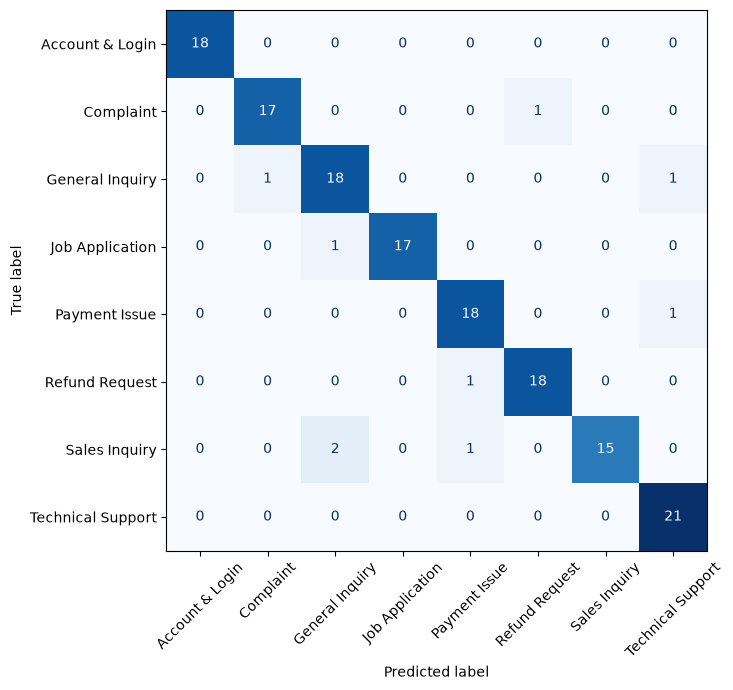

            category          predicted                                         subject                                                                                                                                                                                                                                                                                                                                                                                                       body
2    General Inquiry          Complaint               Check-in time and luggage storage                                                                                         Hello! We are a couple from Germany arriving in Chennai on an early morning flight (landing 5:30 am) on 3 Dec. What are your standard check-in and check-out times at Marigold Residency, and is there somewhere to store luggage or rest in the lobby until the room is ready? Many thanks, Jonas and Elena Weber
35     Payment Issue  Technical Su

In [27]:
import os, matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

os.makedirs("../reports", exist_ok=True)
best = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                     LogisticRegression(max_iter=2000, C=10))
best.fit(X_tr, y_tr)
pred = best.predict(X_va)

print(classification_report(y_va, pred, digits=3))

labels = sorted(y_va.unique())
cm = confusion_matrix(y_va, pred, labels=labels)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.tight_layout(); plt.savefig("../reports/cm_tfidf_lr.png", dpi=150); plt.show()

mask = pred != y_va.values
err = val[mask].copy(); err["predicted"] = pred[mask]
pd.set_option("display.max_colwidth", 220)
print(err[["category", "predicted", "subject", "body"]].to_string())

In [28]:
from sentence_transformers import SentenceTransformer
import numpy as np, time
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

st = SentenceTransformer("all-MiniLM-L6-v2")
T_tr = preprocess_df(train, mode="embedding")
T_va = preprocess_df(val, mode="embedding")

E_tr = st.encode(T_tr, batch_size=32, normalize_embeddings=True, show_progress_bar=True)
t0 = time.time()
E_va = st.encode(T_va, batch_size=32, normalize_embeddings=True)
embed_ms = (time.time() - t0) / len(T_va) * 1000
np.save("../data/E_tr.npy", E_tr); np.save("../data/E_va.npy", E_va)

# A) Logistic Regression on embeddings
lr = LogisticRegression(max_iter=3000, C=10).fit(E_tr, y_tr)
t0 = time.time(); pred_lr = lr.predict(E_va); pred_ms = (time.time() - t0) / len(E_va) * 1000

# B) Similarity only: nearest category centroid (cosine)
cats = sorted(y_tr.unique())
cent = np.vstack([E_tr[(y_tr == c).values].mean(0) for c in cats])
cent /= np.linalg.norm(cent, axis=1, keepdims=True)
pred_cent = np.array(cats)[(E_va @ cent.T).argmax(1)]

for name, p in [("MiniLM + Logistic Regression", pred_lr), ("MiniLM + nearest centroid", pred_cent)]:
    print(f"{name:30s} acc {accuracy_score(y_va, p):.3f} | macro F1 {f1_score(y_va, p, average='macro'):.3f}")
print(f"embedding time {embed_ms:.1f} ms/email + classify {pred_ms:.2f} ms/email")

# Which emails does it get wrong?
bad = pred_lr != y_va.values
e2 = val[bad].copy(); e2["predicted"] = pred_lr[bad]
print(e2[["category", "predicted", "subject"]].to_string())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/23 [00:00<?, ?it/s]

MiniLM + Logistic Regression   acc 0.914 | macro F1 0.915
MiniLM + nearest centroid      acc 0.874 | macro F1 0.875
embedding time 17.7 ms/email + classify 0.04 ms/email
              category          predicted                                           subject
8        Payment Issue     Refund Request        Diwali sale discount missing from my order
35       Payment Issue  Technical Support                          Error 5003 when donating
52       Sales Inquiry  Technical Support                                    emi on laptops
66     Account & Login     Refund Request                         Delete account and refund
67      Refund Request          Complaint                          Wrong medicine delivered
72           Complaint     Refund Request                  No reply from seller for 10 days
80     Account & Login  Technical Support                         2FA screen keeps freezing
81   Technical Support    General Inquiry  Assistance Needed for Microsoft Office 365 Setup
90

In [29]:
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline

trval = pd.concat([train, val], ignore_index=True)
Xt = np.array(preprocess_df(trval), dtype=object)
E_all = np.vstack([E_tr, E_va])            # same row order as trval
y = trval["category"].values
cv = StratifiedKFold(5, shuffle=True, random_state=42)

def tfidf_lr():
    return make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                         LogisticRegression(max_iter=2000, C=10))

res = {"TF-IDF + LR": [], "MiniLM + LR": [], "Ensemble (avg probs)": []}
for tr_i, te_i in cv.split(Xt, y):
    a = tfidf_lr().fit(Xt[tr_i], y[tr_i])
    b = LogisticRegression(max_iter=3000, C=10).fit(E_all[tr_i], y[tr_i])
    pa, pb = a.predict_proba(Xt[te_i]), b.predict_proba(E_all[te_i])
    cls = a.classes_                      # same order as b.classes_
    for k, p in [("TF-IDF + LR", pa), ("MiniLM + LR", pb), ("Ensemble (avg probs)", (pa + pb) / 2)]:
        pred = cls[p.argmax(1)]
        res[k].append((accuracy_score(y[te_i], pred), f1_score(y[te_i], pred, average="macro")))

for k, v in res.items():
    v = np.array(v)
    print(f"{k:22s} acc {v[:,0].mean():.3f} ± {v[:,0].std():.3f} | macro F1 {v[:,1].mean():.3f} ± {v[:,1].std():.3f}")

TF-IDF + LR            acc 0.923 ± 0.011 | macro F1 0.924 ± 0.011
MiniLM + LR            acc 0.914 ± 0.013 | macro F1 0.913 ± 0.012
Ensemble (avg probs)   acc 0.943 ± 0.013 | macro F1 0.943 ± 0.013


In [30]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"

path = DATA / "test_handwritten.csv"
print("looking for:", path, "| exists:", path.exists())

looking for: c:\Users\Pradakshana\email-poc\data\test_handwritten.csv | exists: True


In [31]:
if not path.exists():
    pd.DataFrame(columns=["id","subject","body","category","priority",
                          "type","alt_label","split"]).to_csv(path, index=False)

In [32]:
import numpy as np

cats8 = ["Technical Support","Payment Issue","Account & Login","Sales Inquiry",
         "Complaint","Refund Request","Job Application","General Inquiry"]
plan = {"short":3, "messy":3, "borderline":2, "novel":2}
unk_groups = ["spam","newsletter","wrongrecip","autoreply","nonenglish","unrelated"]

rows = []
for c in cats8:
    slug = c.split()[0].lower()[:4]
    for t, n in plan.items():
        for i in range(1, n+1):
            rows.append(dict(id=f"{slug}-{t}-{i}", subject="", body="", category=c,
                             priority="", type=t, alt_label="", split="test"))

rng = np.random.default_rng(42)
for g in unk_groups:
    dev_idx = set(rng.choice(5, size=2, replace=False) + 1)   # 2 dev per group
    for i in range(1, 6):
        rows.append(dict(id=f"unk-{g}-{i}", subject="", body="", category="Unknown",
                         priority="NA", type="unknown", alt_label="",
                         split="dev" if i in dev_idx else "test"))

scaffold = pd.DataFrame(rows)
out = DATA / "test_handwritten.csv"
if out.exists() and len(pd.read_csv(out)) > 0:
    print("File already has rows, not overwriting.")
else:
    scaffold.to_csv(out, index=False, encoding="utf-8")
    print(len(scaffold), "rows (80 category + 30 Unknown); dev:", (scaffold.split=="dev").sum())

File already has rows, not overwriting.


In [33]:
import sys, importlib
sys.path.insert(0, str(ROOT))          # lets "from src..." work from notebooks/

from src import decision
importlib.reload(decision)             # picks up edits to decision.py without restarting the kernel
from src.decision import load_config, decide

cfg = load_config(ROOT / "config" / "pipeline.yaml")

In [34]:
from sklearn.base import BaseEstimator
for name, obj in list(globals().items()):
    if isinstance(obj, BaseEstimator) and hasattr(obj, "classes_"):
        print(name, type(obj).__name__)
    elif callable(obj) and any(k in name.lower() for k in ["tfidf", "minilm", "ensemble", "proba"]):
        print(name, "-> function")

TfidfVectorizer -> function
clf CalibratedClassifierCV
pipe Pipeline
best Pipeline
lr LogisticRegression
tfidf_lr -> function
a Pipeline
b LogisticRegression


In [35]:
from sklearn.base import BaseEstimator
found = [(n, type(o).__name__) for n, o in globals().items()
         if isinstance(o, BaseEstimator) and hasattr(o, "classes_")]
print(found if found else "no fitted classifiers in this kernel")

[('clf', 'CalibratedClassifierCV'), ('pipe', 'Pipeline'), ('best', 'Pipeline'), ('lr', 'LogisticRegression'), ('a', 'Pipeline'), ('b', 'LogisticRegression')]


In [36]:
from src.preprocess import preprocess_df
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sentence_transformers import SentenceTransformer

X_tr_t = preprocess_df(train, mode="tfidf")
X_va_t = preprocess_df(val,   mode="tfidf")
X_tr_e = preprocess_df(train, mode="embedding")
X_va_e = preprocess_df(val,   mode="embedding")

vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)   # swap in your CV settings
lr_t = LogisticRegression(max_iter=2000).fit(vec.fit_transform(X_tr_t), train.category)

st = SentenceTransformer("all-MiniLM-L6-v2")
lr_e = LogisticRegression(max_iter=2000).fit(st.encode(list(X_tr_e)), train.category)

assert (lr_t.classes_ == lr_e.classes_).all()
classes = np.array(lr_t.classes_)
assert set(classes) == set(cfg["categories"]), set(classes) ^ set(cfg["categories"])

proba_val = (lr_t.predict_proba(vec.transform(X_va_t)) +
             lr_e.predict_proba(st.encode(list(X_va_e)))) / 2
print(proba_val.shape, classes)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

(151, 8) ['Account & Login' 'Complaint' 'General Inquiry' 'Job Application'
 'Payment Issue' 'Refund Request' 'Sales Inquiry' 'Technical Support']


In [37]:
res = pd.DataFrame([decide(p, classes, cfg) for p in proba_val])
res["correct"] = res.predicted.values == val.category.values
print(res.groupby("action").agg(n=("correct","size"), acc=("correct","mean")))
print(res.groupby("correct").confidence.describe())

                   n       acc
action                        
manual_review    140  0.914286
route_with_flag   11  1.000000
         count      mean       std       min       25%       50%       75%  \
correct                                                                      
False     12.0  0.305851  0.055866  0.208276  0.261262  0.308581  0.334073   
True     139.0  0.442471  0.101031  0.198646  0.370290  0.444769  0.513641   

              max  
correct            
False    0.389088  
True     0.645649  


In [38]:
from scipy.optimize import minimize_scalar
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline

skf = StratifiedKFold(5, shuffle=True, random_state=42)
y_tr = train.category.values
E_tr = st.encode(list(X_tr_e))
E_va = st.encode(list(X_va_e))

def oof(model, X):
    return cross_val_predict(model, X, y_tr, cv=skf, method="predict_proba")

# 1) pick C for each model by out-of-fold log loss (train only)
best = {}
for name, mk, X in [
    ("tfidf", lambda C: make_pipeline(TfidfVectorizer(ngram_range=(1,2), sublinear_tf=True),
                                      LogisticRegression(C=C, max_iter=3000)), X_tr_t),
    ("emb",   lambda C: LogisticRegression(C=C, max_iter=3000), E_tr),
]:
    scores = {C: log_loss(y_tr, oof(mk(C), X), labels=classes) for C in [1, 10, 30, 100, 300]}
    best[name] = min(scores, key=scores.get)
    print(name, {k: round(v, 3) for k, v in scores.items()}, "-> C =", best[name])

# 2) OOF ensemble, then fit one temperature on it
P_oof = (oof(make_pipeline(TfidfVectorizer(ngram_range=(1,2), sublinear_tf=True),
                           LogisticRegression(C=best["tfidf"], max_iter=3000)), X_tr_t) +
         oof(LogisticRegression(C=best["emb"], max_iter=3000), E_tr)) / 2

def sharpen(P, T):
    Q = np.power(P, 1.0 / T)
    return Q / Q.sum(axis=1, keepdims=True)

T = minimize_scalar(lambda t: log_loss(y_tr, sharpen(P_oof, t), labels=classes),
                    bounds=(0.1, 3.0), method="bounded").x
print("temperature:", round(T, 3), "(<1 sharpens, >1 softens)")

# 3) refit on full train with the chosen C, apply T, evaluate on val
lr_t = make_pipeline(TfidfVectorizer(ngram_range=(1,2), sublinear_tf=True),
                     LogisticRegression(C=best["tfidf"], max_iter=3000)).fit(X_tr_t, y_tr)
lr_e = LogisticRegression(C=best["emb"], max_iter=3000).fit(E_tr, y_tr)
assert (lr_t.classes_ == lr_e.classes_).all() and (lr_t.classes_ == classes).all()

proba_val = sharpen((lr_t.predict_proba(X_va_t) + lr_e.predict_proba(E_va)) / 2, T)

res = pd.DataFrame([decide(p, classes, cfg) for p in proba_val])
res["correct"] = res.predicted.values == val.category.values
print(res.groupby("action").agg(n=("correct","size"), acc=("correct","mean")))
print(res.groupby("correct").confidence.describe())

tfidf {1: 1.455, 10: 0.78, 30: 0.609, 100: 0.483, 300: 0.405} -> C = 300
emb {1: 0.668, 10: 0.359, 30: 0.32, 100: 0.313, 300: 0.323} -> C = 100
temperature: 0.517 (<1 sharpens, >1 softens)
                   n       acc
action                        
auto_route       130  0.992308
manual_review      5  0.400000
route_with_flag   16  0.750000
         count      mean       std       min       25%       50%       75%  \
correct                                                                      
False      8.0  0.684419  0.154648  0.499057  0.555453  0.678759  0.808446   
True     143.0  0.960179  0.089006  0.532994  0.980532  0.997314  0.999518   

              max  
correct            
False    0.921248  
True     0.999998  


In [39]:
hw = pd.read_csv(DATA / "test_handwritten.csv")
print(hw[hw.split == "dev"][["id", "subject", "body"]].to_string())

                   id                                               subject                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  body
3        tech-messy-1                                                   NaN                                                                                                                                                                                                                                                                                           

In [40]:
hw = pd.read_csv(DATA / "test_handwritten.csv", dtype={"subject": str, "body": str})
print(hw[hw.split == "dev"][["id"]].to_string())

                   id
3        tech-messy-1
8        tech-novel-1
13       paym-messy-1
18       paym-novel-1
23       acco-messy-1
28       acco-novel-1
33       sale-messy-1
38       sale-novel-1
43       comp-messy-1
48       comp-novel-1
53       refu-messy-1
58       refu-novel-1
63        job-messy-1
68        job-novel-1
73       gene-messy-1
78       gene-novel-1
80         unk-spam-1
83         unk-spam-4
86   unk-newsletter-2
87   unk-newsletter-3
90   unk-wrongrecip-1
93   unk-wrongrecip-4
95    unk-autoreply-1
97    unk-autoreply-3
102  unk-nonenglish-3
103  unk-nonenglish-4
107   unk-unrelated-3
108   unk-unrelated-4


In [41]:
from sklearn.preprocessing import normalize

def max_sim(E_q, E_ref):
    return (normalize(E_q) @ normalize(E_ref).T).max(1)

val_sim = max_sim(E_va, E_tr)
print("val sim percentiles (1,5,10,25,50):", np.percentile(val_sim, [1, 5, 10, 25, 50]).round(3))

# Do low-similarity val emails tend to be the wrong ones?
res["sim"] = val_sim
print(res.groupby("correct").sim.describe().round(3))

val sim percentiles (1,5,10,25,50): [0.358 0.418 0.454 0.502 0.566]
         count   mean    std    min    25%    50%    75%    max
correct                                                        
False      8.0  0.551  0.129  0.356  0.485  0.542  0.625  0.762
True     143.0  0.573  0.102  0.343  0.502  0.567  0.634  0.963


In [42]:
def topk_sim(E_q, E_ref, k=3):
    S = normalize(E_q) @ normalize(E_ref).T
    return np.sort(S, axis=1)[:, -k:].mean(1)

res["sim_top3"] = topk_sim(E_va, E_tr)
print("top3 percentiles (1,5,10,25,50):",
      np.percentile(res.sim_top3, [1, 5, 10, 25, 50]).round(3))
print(res.groupby("correct").sim_top3.describe().round(3))

top3 percentiles (1,5,10,25,50): [0.341 0.385 0.43  0.463 0.527]
         count   mean    std    min    25%    50%    75%    max
correct                                                        
False      8.0  0.501  0.110  0.329  0.450  0.511  0.598  0.620
True     143.0  0.527  0.083  0.312  0.463  0.527  0.584  0.729


In [43]:
hw = pd.read_csv(DATA / "test_handwritten.csv", dtype={"subject": str, "body": str})
mask = hw["id"].str.endswith(("-messy-1", "-novel-1"))
hw.loc[mask, "split"] = "dev"
hw.to_csv(DATA / "test_handwritten.csv", index=False, encoding="utf-8")
print(hw.groupby(["split", "category"]).size().unstack(fill_value=0))

category  Account & Login  Complaint  General Inquiry  Job Application  \
split                                                                    
dev                     2          2                2                2   
test                    8          8                8                8   

category  Payment Issue  Refund Request  Sales Inquiry  Technical Support  \
split                                                                       
dev                   2               2              2                  2   
test                  8               8              8                  8   

category  Unknown  
split              
dev            12  
test           18  


In [44]:
rows = {
 "unk-spam-1": ("National Security Department: FaceTime vulnerability",
  "National Security Department. A vulnerability has been identified in the Apple FaceTime mobile applications that allows an attacker to record calls and videos from your mobile device without your knowledge. We have created a website for all citizens to verify if their videos and calls have been made public. To perform the verification, please use the following link: Facetime Verification. This website will be available for 72 hours."),
 "unk-spam-4": ("Hey I'm Interested in STAP Program",
  "Hey there! This is a training-cum-internship program designed for individuals with little to no prior experience. Our goal is to identify and nurture raw talent by providing hands-on learning opportunities in a real R&D startup environment. If you're genuinely interested in learning, growing, and gaining practical exposure, please join our community through the link below to learn more about the program and the next steps. https://chat.whatsapp.com/xxxxxxxx We look forward to connecting with you, to teach you and to mentor you. Regards, Team Alpha AI Company"),
 "unk-newsletter-2": ("Earn up to 3,000 bonus KrisFlyer miles",
  "Shop more, earn more KrisFlyer miles! From now until 15 October, earn 1,000 bonus KrisFlyer miles when you purchase any 2 items on KrisShop, or unlock 3,000 bonus miles when you purchase 4 items with a minimum spend of S$200. Travelling soon? Pre-order your favourites for in-flight delivery and enjoy 3X bonus miles plus an additional S$20 off with promo code TRIP20, when you spend a minimum of S$400 in a single transaction. Start shopping today! SHOP NOW. This is an automatically generated message. Please do not reply to this address. Unsubscribe"),
 "unk-newsletter-3": ("Celebrate Dhanteras & Diwali with GRT Online",
  "Dhanteras & Diwali Special! Back on High Demand! Extra 2% Instant Discount with HDFC Credit Cards*. WhatsApp Now. Click here to unsubscribe from this newsletter."),
 "unk-wrongrecip-1": ("Re: Application for AI/ML Intern",
  "Wrong destination. This is an email-id for coordination of IEEE CVMI 2026. Best. CVMI2026 Organizing Committee"),
 "unk-wrongrecip-4": ("Japan tour documents (07-17 June)",
  "Dear Sir, Please find attached herewith; Japan tour documents. 1) Hotel Vouchers 2) Sightseeing vouchers 3) TRAIN tickets 4) Tokyo arrival transfers. Pending: OSKA departure transfers vouchers. Regards"),
 "unk-autoreply-1": ("Your Tickets",
  "Your booking is confirmed! 07:25pm | Tue, 25 Aug, 2026. PVR: Sathyam, Royapettah, Chennai. ORDER SUMMARY. Ticket amount Rs.519.00, 3 tickets. Convenience fees Rs.95.58. Offer processing fee Rs.15.34. Discount Rs.173.00. Amount paid Rs.456.92. Payment type: Credit Card/Debit Card. This transaction can be cancelled up to 20 min(s) before the show as per cinema cancellation policy."),
 "unk-autoreply-3": ("Share your thoughts about your recent purchase",
  "Hi, we fulfilled your order from our store 20 days ago and would love to get your feedback. What do you think about Black Plain Pure Cotton Side Corset Short Kurti? Rating. Review Title. Review content. Write review on the web. We really appreciate your feedback. Thank you! You have received this email because you made a purchase from our store. Unsubscribe from review request emails"),
 "unk-nonenglish-3": ("ऑर्डर के बारे में",
  "नमस्ते, मेरा ऑर्डर अभी तक नहीं पहुँचा है। कृपया जल्दी बताइए कि वह कब तक आएगा।"),
 "unk-nonenglish-4": ("உள்நுழைவு பிரச்சினை",
  "வணக்கம், என் கணக்கில் உள்நுழைய முடியவில்லை. தயவுசெய்து உதவுங்கள்."),
 "unk-unrelated-3": ("Biryani recommendation",
  "Hi, can you recommend a good place for biryani near T Nagar? Visiting Chennai this weekend with family."),
 "unk-unrelated-4": ("weather",
  "what's the weather going to be like in Delhi tomorrow? need to decide whether to carry an umbrella"),
}

hw = pd.read_csv(DATA / "test_handwritten.csv", dtype=str, keep_default_na=False)
assert set(rows) <= set(hw["id"]), set(rows) - set(hw["id"])
for i, (s, b) in rows.items():
    hw.loc[hw["id"] == i, ["subject", "body"]] = [s, b]
hw.to_csv(DATA / "test_handwritten.csv", index=False, encoding="utf-8")
print(hw[hw.split == "dev"].groupby("category").apply(lambda g: (g.body.str.len() > 0).sum()))

category
Account & Login       2
Complaint             2
General Inquiry       2
Job Application       2
Payment Issue         2
Refund Request        2
Sales Inquiry         2
Technical Support     2
Unknown              12
dtype: int64


In [45]:
rows = {
 "unk-spam-2": ("UK National Lottery International Promotion",
  "We happily announce to you the draw (#954) of the UK NATIONAL LOTTERY online Sweepstakes International program. Your e-mail address attached to ticket number 013-2316-2002-577 won in the 2nd category. You have been approved to claim a total sum of £1,000,000.00 shared among the first ten lucky winners. Please keep your winning information confidential until your claims have been processed. To file your claim, contact our CLAIM AGENT and submit your full name, telephone number, reference number and contact address. All winnings must be claimed not later than 29th of September. Congratulations once more."),
 "unk-spam-3": ("Euro-Afro-American Sweepstake Lottery",
  "We happily announce to you the draw of the Euro-Afro-American Sweepstake Lottery International program. Your e-mail address attached to ticket number B9564 75604545 188 won you the lottery in the 2nd category. You have been approved to claim a total sum of £1,350,000.00. In compliance with the sponsoring bodies, you are to make a remittance of not less than 10 percent of your winnings to a charity organisation after receiving your allocation. Please contact our corresponding agent in South Africa immediately for quick and urgent release of your funds. Quote your security code in all correspondence and keep your winning information confidential. All winnings must be claimed within 30 days."),
 "unk-spam-5": ("AMONG THE TOYOTA WINNER",
  "We are pleased to inform you that you are among the winners of the TOYOTA CAR INTERNATIONAL PROMOTION PROGRAM. Your email address, attached to ticket number 7192261319, won in the Second Category of the TOYOTA FORTUNE LOTTO DRAW. You have been approved for the payment of US$500,000 in cash, including a Toyota car. Your cheque is now with the payee center. Contact your agent and give your full names, address and contact number, country of origin, occupation and age. Reply to your agent immediately."),
}

hw = pd.read_csv(DATA / "test_handwritten.csv", dtype=str, keep_default_na=False)
assert set(rows) <= set(hw["id"])
for i, (s, b) in rows.items():
    hw.loc[hw["id"] == i, ["subject", "body"]] = [s, b]
hw.to_csv(DATA / "test_handwritten.csv", index=False, encoding="utf-8")
print(hw[hw.id.isin(rows)][["id", "split", "category"]])

            id split category
81  unk-spam-2  test  Unknown
82  unk-spam-3  test  Unknown
84  unk-spam-5  test  Unknown


In [46]:
hw = pd.read_csv(DATA / "test_handwritten.csv", dtype=str, keep_default_na=False)
hw["filled"] = hw["body"].str.len() > 0
print(hw.groupby(["split", "category"])["filled"].sum().unstack(fill_value=0))

category  Account & Login  Complaint  General Inquiry  Job Application  \
split                                                                    
dev                     2          2                2                2   
test                    8          8                8                8   

category  Payment Issue  Refund Request  Sales Inquiry  Technical Support  \
split                                                                       
dev                   2               2              2                  2   
test                  8               8              8                  8   

category  Unknown  
split              
dev            12  
test           18  


In [47]:
hw = pd.read_csv(DATA / "test_handwritten.csv", dtype=str, keep_default_na=False,
                 encoding="cp1252", encoding_errors="replace")
fix = {
 "unk-nonenglish-3": ("ऑर्डर के बारे में",
   "नमस्ते, मेरा ऑर्डर अभी तक नहीं पहुँचा है। कृपया जल्दी बताइए कि वह कब तक आएगा।"),
 "unk-nonenglish-4": ("உள்நுழைவு பிரச்சினை",
   "வணக்கம், என் கணக்கில் உள்நுழைய முடியவில்லை. தயவுசெய்து உதவுங்கள்."),
}
for i, (s, b) in fix.items():
    hw.loc[hw.id == i, ["subject", "body"]] = [s, b]
for i in ["unk-spam-2", "unk-spam-3"]:
    hw.loc[hw.id == i, "body"] = hw.loc[hw.id == i, "body"].str.replace("Â£", "£", regex=False)
hw.to_csv(DATA / "test_handwritten.csv", index=False, encoding="utf-8")

# verify: re-read as UTF-8 and look for any remaining damage
chk = pd.read_csv(DATA / "test_handwritten.csv", dtype=str, keep_default_na=False, encoding="utf-8")
bad = chk[(chk.subject + chk.body).str.contains("Ã|Â|â€|�|à¤|à®")]
print("rows still damaged:", bad.id.tolist())
print(chk.loc[chk.id == "unk-nonenglish-3", "body"].values[0])
print(chk.loc[chk.id == "comp-messy-1", "body"].values[0])

rows still damaged: ['paym-short-3', 'paym-novel-2', 'acco-short-3', 'acco-messy-2', 'acco-borderline-1', 'comp-messy-1', 'comp-messy-3', 'comp-novel-2', 'refu-messy-2', 'refu-borderline-2', 'refu-novel-1', 'job-borderline-2', 'gene-borderline-1', 'unk-nonenglish-1', 'unk-nonenglish-5']
नमस्ते, मेरा ऑर्डर अभी तक नहीं पहुँचा है। कृपया जल्दी बताइए कि वह कब तक आएगा।
Staff very unprofessional already emailed about this issue but havenâ€™t received any replies.


In [48]:
from sklearn.preprocessing import normalize

hw = pd.read_csv(DATA / "test_handwritten.csv", dtype=str, keep_default_na=False, encoding="utf-8")
dev = hw[(hw.split == "dev") & (hw.body.str.len() > 0)].copy()
print("dev rows:", len(dev), "(expect 28)")

X_d_t = preprocess_df(dev, mode="tfidf")
X_d_e = preprocess_df(dev, mode="embedding")
E_d = st.encode(list(X_d_e))
P_d = sharpen((lr_t.predict_proba(X_d_t) + lr_e.predict_proba(E_d)) / 2, T)

dev["conf"] = P_d.max(1)
dev["pred"] = classes[P_d.argmax(1)]
dev["sim"] = (normalize(E_d) @ normalize(E_tr).T).max(1)

pd.set_option("display.width", 200)
print(dev[["id", "category", "pred", "conf", "sim"]].round(3).to_string(index=False))

dev rows: 28 (expect 28)
              id          category              pred  conf   sim
    tech-messy-1 Technical Support Technical Support 0.999 0.558
    tech-novel-1 Technical Support Technical Support 0.986 0.577
    paym-messy-1     Payment Issue     Payment Issue 0.775 0.642
    paym-novel-1     Payment Issue     Payment Issue 0.962 0.580
    acco-messy-1   Account & Login   Account & Login 0.999 0.825
    acco-novel-1   Account & Login   Account & Login 1.000 0.611
    sale-messy-1     Sales Inquiry     Sales Inquiry 1.000 0.523
    sale-novel-1     Sales Inquiry     Sales Inquiry 0.998 0.598
    comp-messy-1         Complaint         Complaint 0.976 0.522
    comp-novel-1         Complaint         Complaint 0.994 0.594
    refu-messy-1    Refund Request    Refund Request 1.000 0.671
    refu-novel-1    Refund Request    Refund Request 1.000 0.612
     job-messy-1   Job Application   Job Application 1.000 0.585
     job-novel-1   Job Application   Job Application 1.000 0.513


In [49]:
hw = pd.read_csv(DATA / "test_handwritten.csv", dtype=str, keep_default_na=False, encoding="utf-8")
hw["filled"] = hw["body"].str.len() > 0
print(hw.groupby(["split", "category"])["filled"].sum().unstack(fill_value=0))
print(hw.loc[hw.id == "comp-messy-1", ["split", "body"]].values)

category  Account & Login  Complaint  General Inquiry  Job Application  Payment Issue  Refund Request  Sales Inquiry  Technical Support  Unknown
split                                                                                                                                           
dev                     2          2                2                2              2               2              2                  2       12
test                    8          8                8                8              8               8              8                  8       18
[['dev'
  'Staff very unprofessional already emailed about this issue but havenâ€™t received any replies.']]


In [50]:
import shutil
shutil.copy(DATA / "test_handwritten.csv", DATA / "test_handwritten_backup.csv")

rows = {
 "tech-messy-1": "my wifi router is constantly restarting",
 "tech-novel-1": "after rebooting my smart meter it still shows error. Could someone check?",
 "paym-messy-1": "money has been taken out but booking not confirmed",
 "paym-novel-1": "I have paid my college fees online however my balance is being taken from my account but on the portal it shows as unpaid.",
 "acco-messy-1": "no otp received I have tried many no. of  times and cannot log in",
 "acco-novel-1": "My account on the government portal has been locked after I entered my details incorrectly a few times. How can I get back into my account?",
 "sale-messy-1": "price for 50pcs? Any discount for bulk orders?",
 "sale-novel-1": "We are looking to fit some solar panels. Could you give us a quote for the amount needed? Including installation and maintenance costs.",
 "comp-messy-1": "Staff very unprofessional already emailed about this issue but haven’t received any replies.",
 "comp-novel-1": "Parcel has been delayed for a number of days. The service centre have not given me any clear information. Please could you look into this?",
 "refu-messy-1": "Cancelled 2 weeks ago. Still no refund. Please return my money.",
 "refu-novel-1": "I cancelled my online course however I haven’t received my refund yet. Could you tell me when I will receive my refund?",
 "job-messy-1": "Hi I am looking for a part time job. My cv is attached. Please let me know if there is anything available.",
 "job-novel-1": "Dear Hiring Team, I am interested in applying for the of AI engineer. I have attached my resume of refrence. Please let me know if my skills match the position.",
 "gene-messy-1": "Hi! what time do you finish today?",
 "gene-novel-1": "Hello, We are holding a community event next month and would be interested in discussing a possible sponsorship or partnership. Could you please provide us with the correct contact details and any requirements?",
}

hw = pd.read_csv(DATA / "test_handwritten.csv", dtype=str, keep_default_na=False, encoding="utf-8")
assert set(rows) <= set(hw["id"]), set(rows) - set(hw["id"])
for i, b in rows.items():
    assert hw.loc[hw.id == i, "split"].iloc[0] == "dev", i
    hw.loc[hw.id == i, "body"] = b
hw.to_csv(DATA / "test_handwritten.csv", index=False, encoding="utf-8")

chk = pd.read_csv(DATA / "test_handwritten.csv", dtype=str, keep_default_na=False, encoding="utf-8")
chk["filled"] = chk["body"].str.len() > 0
print(chk.groupby(["split", "category"])["filled"].sum().unstack(fill_value=0))

category  Account & Login  Complaint  General Inquiry  Job Application  Payment Issue  Refund Request  Sales Inquiry  Technical Support  Unknown
split                                                                                                                                           
dev                     2          2                2                2              2               2              2                  2       12
test                    8          8                8                8              8               8              8                  8       18


In [51]:
from sklearn.preprocessing import normalize

hw = pd.read_csv(DATA / "test_handwritten.csv", dtype=str, keep_default_na=False, encoding="utf-8")
dev = hw[(hw.split == "dev") & (hw.body.str.len() > 0)].copy()
print("dev rows:", len(dev), "(expect 28)")

X_d_t = preprocess_df(dev, mode="tfidf")
X_d_e = preprocess_df(dev, mode="embedding")
E_d = st.encode(list(X_d_e))
P_d = sharpen((lr_t.predict_proba(X_d_t) + lr_e.predict_proba(E_d)) / 2, T)

dev["conf"] = P_d.max(1)
dev["pred"] = classes[P_d.argmax(1)]
dev["sim"] = (normalize(E_d) @ normalize(E_tr).T).max(1)

pd.set_option("display.width", 200)
print(dev[["id", "category", "pred", "conf", "sim"]].round(3).to_string(index=False))

dev rows: 28 (expect 28)
              id          category              pred  conf   sim
    tech-messy-1 Technical Support Technical Support 0.999 0.558
    tech-novel-1 Technical Support Technical Support 0.986 0.577
    paym-messy-1     Payment Issue     Payment Issue 0.775 0.642
    paym-novel-1     Payment Issue     Payment Issue 0.962 0.580
    acco-messy-1   Account & Login   Account & Login 0.999 0.825
    acco-novel-1   Account & Login   Account & Login 1.000 0.611
    sale-messy-1     Sales Inquiry     Sales Inquiry 1.000 0.523
    sale-novel-1     Sales Inquiry     Sales Inquiry 0.998 0.598
    comp-messy-1         Complaint         Complaint 0.977 0.525
    comp-novel-1         Complaint         Complaint 0.994 0.594
    refu-messy-1    Refund Request    Refund Request 1.000 0.671
    refu-novel-1    Refund Request    Refund Request 1.000 0.627
     job-messy-1   Job Application   Job Application 1.000 0.585
     job-novel-1   Job Application   Job Application 1.000 0.513


In [52]:
import importlib
from src import decision
importlib.reload(decision)
from src.decision import load_config, decide
cfg = load_config(ROOT / "config" / "pipeline.yaml")
print(cfg["thresholds"])

{'auto_route': 0.85, 'review_flag': 0.6, 'min_margin': 0.0, 'min_similarity': 0.42}


In [53]:
out = pd.DataFrame([decide(P_d[i], classes, cfg, sim=dev.sim.iloc[i]) for i in range(len(dev))])
out["id"] = dev.id.values
out["true"] = dev.category.values
out["is_unk"] = out.true == "Unknown"
out["to_review"] = out.action == "manual_review"

print("Unknown caught:", out[out.is_unk].to_review.sum(), "/", out.is_unk.sum())
print("In-category wrongly sent to manual review:", out[~out.is_unk].to_review.sum(), "/", (~out.is_unk).sum())
print(out[["id", "true", "category", "action", "reason", "confidence"]].round(3).to_string(index=False))

Unknown caught: 8 / 12
In-category wrongly sent to manual review: 0 / 16
              id              true          category          action                 reason  confidence
    tech-messy-1 Technical Support Technical Support      auto_route                    NaN       0.999
    tech-novel-1 Technical Support Technical Support      auto_route                    NaN       0.986
    paym-messy-1     Payment Issue     Payment Issue route_with_flag      medium confidence       0.775
    paym-novel-1     Payment Issue     Payment Issue      auto_route                    NaN       0.962
    acco-messy-1   Account & Login   Account & Login      auto_route                    NaN       0.999
    acco-novel-1   Account & Login   Account & Login      auto_route                    NaN       1.000
    sale-messy-1     Sales Inquiry     Sales Inquiry      auto_route                    NaN       1.000
    sale-novel-1     Sales Inquiry     Sales Inquiry      auto_route                    NaN    

In [54]:
from sklearn.metrics import classification_report, f1_score, accuracy_score

pri_tr, pri_va = train["priority"], val["priority"]

# baseline: the most common priority within each (true) category
mode = train.groupby("category")["priority"].agg(lambda s: s.mode()[0])
base = val["category"].map(mode)
print("category-only baseline: acc %.3f | macro F1 %.3f" %
      (accuracy_score(pri_va, base), f1_score(pri_va, base, average="macro")))

pri_model = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    LogisticRegression(max_iter=3000, C=10, class_weight="balanced"))
pri_model.fit(X_tr_t, pri_tr)
pri_pred = pri_model.predict(X_va_t)
print(classification_report(pri_va, pri_pred, digits=3))

category-only baseline: acc 0.603 | macro F1 0.458
              precision    recall  f1-score   support

        High      0.778     0.636     0.700        33
         Low      0.833     0.769     0.800        52
      Medium      0.711     0.818     0.761        66

    accuracy                          0.762       151
   macro avg      0.774     0.741     0.754       151
weighted avg      0.768     0.762     0.761       151



In [55]:
mask = (pri_va.values == "High") & (pri_pred != "High")
miss = val[mask].copy()
miss["pred_priority"] = pri_pred[mask]
pd.set_option("display.max_colwidth", 230); pd.set_option("display.width", 250)
print(miss[["category", "pred_priority", "subject", "body"]].to_string())

tf = pri_model.steps[0][1]; clf = pri_model.steps[-1][1]
coef = clf.coef_[list(clf.classes_).index("High")]
names = np.array(tf.get_feature_names_out())
print("\nTop terms for High:", list(names[np.argsort(coef)[-25:][::-1]]))

              category pred_priority                                                  subject                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    body
28     Account & Login           Low                         Suspicious session on my profile                                                                     

In [56]:
import re
from sklearn.model_selection import StratifiedKFold, cross_val_predict

def raw_text(df):
    return (df["subject"].fillna("") + " " + df["body"].fillna("")).str.lower()

RULES = {
 "urgent":     r"\burgent(ly)?\b|\bemergency\b",
 "asap":       r"\basap\b|as soon as possible|\bimmediate(ly)?\b|right away|right now|at once",
 "deadline":   r"\b(today|tonight|tomorrow)\b|\bby \d{1,2}(:\d\d)? ?(am|pm)\b|\bby (end of (the )?day|eod)\b|within (24|48) hours",
 "escalation": r"escalat|legal action|consumer (forum|court)|regulator|social media|public review|lawyer|chargeback",
 "security":   r"\bhack|unauthori[sz]ed|\bsomeone (changed|logged|accessed|else)|isn't mine|\bnot me\b|suspicious|compromis|\bscam|fraud|stolen",
 "money_lost": r"(charged|debited|billed)( me)? (twice|two times|2x)|double (charged|debited|billing)|(deducted|debited|taken out|gone from)|money (was )?(deducted|debited|gone|taken)",
 "outage":     r"\bdown\b|outage|nobody (can|has been able)|none of our|whole team|all (our )?(users|staff|employees)|crash(es|ed|ing)?\b",
 "safety":     r"gas (smell|leak)|\bfire\b|smoke|injur|ambulance|stuck (in|between)|medication|elderly|\bunsafe\b",
}
NEG = r"\b(not|no|isn't|nothing)\b[^.]{0,15}\b(urgent|rush|hurry)\b|low priority|whenever (you|it)"

def rule_hits(df):
    t = raw_text(df)
    H = pd.DataFrame({k: t.str.contains(v, regex=True) for k, v in RULES.items()})
    H.loc[t.str.contains(NEG, regex=True), ["urgent", "asap", "deadline"]] = False
    return H

# ---- 1) Evaluate each rule on TRAIN, using out-of-fold ML predictions ----
skf = StratifiedKFold(5, shuffle=True, random_state=42)
oof_pri = cross_val_predict(pri_model, X_tr_t, pri_tr, cv=skf)
H_tr = rule_hits(train)
is_high = (pri_tr.values == "High")
ml_not_high = (oof_pri != "High")

rows = []
for k in H_tr:
    m = H_tr[k].values
    mm = m & ml_not_high                      # rule fires where ML says non-High
    gain, loss = (mm & is_high).sum(), (mm & ~is_high).sum()
    rows.append(dict(rule=k, fires=m.sum(), high_rate=round(is_high[m].mean(), 2) if m.sum() else np.nan,
                     override_fires=mm.sum(), gain=gain, loss=loss,
                     override_precision=round(gain / mm.sum(), 2) if mm.sum() else np.nan))
print("High base rate in train:", is_high.mean().round(3))
print(pd.DataFrame(rows).to_string(index=False))
print("ML-only High recall (OOF, train):", ((oof_pri == "High") & is_high).sum() / is_high.sum())

High base rate in train: 0.177
      rule  fires  high_rate  override_fires  gain  loss  override_precision
    urgent     45       0.73              13     6     7                0.46
      asap     34       0.71              17     9     8                0.53
  deadline     51       0.63              21     7    14                0.33
escalation     15       0.87               7     5     2                0.71
  security     12       0.75               4     2     2                0.50
money_lost     30       0.73               8     4     4                0.50
    outage     22       0.41              17     5    12                0.29
    safety     11       0.45              10     4     6                0.40
ML-only High recall (OOF, train): 0.576


C:\Users\Pradakshana\AppData\Local\Temp\ipykernel_23588\1754483740.py:21: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  H = pd.DataFrame({k: t.str.contains(v, regex=True) for k, v in RULES.items()})
C:\Users\Pradakshana\AppData\Local\Temp\ipykernel_23588\1754483740.py:22: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  H.loc[t.str.contains(NEG, regex=True), ["urgent", "asap", "deadline"]] = False


In [57]:
def combo(keep):
    if keep:
        fired = H_tr[keep].any(axis=1).values
        hy = np.where(fired, "High", oof_pri)
    else:
        hy = oof_pri
    ch = hy != oof_pri
    tp = ((hy == "High") & is_high).sum()
    return dict(rules="+".join(keep) or "ML only", overrides=ch.sum(),
                gain=(ch & is_high).sum(), loss=(ch & ~is_high).sum(),
                high_recall=round(tp / is_high.sum(), 3),
                high_prec=round(tp / (hy == "High").sum(), 3),
                macro_f1=round(f1_score(pri_tr.values, hy, average="macro"), 3))

cands = [[], ["asap", "escalation", "money_lost"],
         ["asap", "escalation", "money_lost", "urgent"],
         ["asap", "escalation", "money_lost", "urgent", "security"]]
print(pd.DataFrame([combo(k) for k in cands]).to_string(index=False))

                                     rules  overrides  gain  loss  high_recall  high_prec  macro_f1
                                   ML only          0     0     0        0.576      0.692     0.722
                asap+escalation+money_lost         31    17    14        0.712      0.659     0.741
         asap+escalation+money_lost+urgent         43    22    21        0.752      0.639     0.742
asap+escalation+money_lost+urgent+security         47    24    23        0.768      0.636     0.744


In [58]:
KEEP = ["asap", "escalation", "money_lost", "urgent", "security"]

def hybrid_priority(df, ml_pred):
    H = rule_hits(df)[KEEP]
    fired = H.any(axis=1).values
    why = H.apply(lambda r: ", ".join(r.index[r]), axis=1).values
    return np.where(fired, "High", ml_pred), why

ml_va = pri_model.predict(X_va_t)
hy_va, why = hybrid_priority(val, ml_va)
y = pri_va.values

for name, p in [("ML only", ml_va), ("Hybrid", hy_va)]:
    tp = ((p == "High") & (y == "High")).sum()
    print(f"{name:8s} acc {accuracy_score(y, p):.3f} | macro F1 {f1_score(y, p, average='macro'):.3f} "
          f"| High recall {tp/(y=='High').sum():.2f} precision {tp/(p=='High').sum():.2f}")

ch = hy_va != ml_va
print(f"overrides: {ch.sum()} | became correct: {((hy_va == y) & ch).sum()} | became wrong: {((hy_va != y) & ch).sum()}")

C:\Users\Pradakshana\AppData\Local\Temp\ipykernel_23588\1754483740.py:21: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  H = pd.DataFrame({k: t.str.contains(v, regex=True) for k, v in RULES.items()})
C:\Users\Pradakshana\AppData\Local\Temp\ipykernel_23588\1754483740.py:22: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  H.loc[t.str.contains(NEG, regex=True), ["urgent", "asap", "deadline"]] = False


ML only  acc 0.762 | macro F1 0.754 | High recall 0.64 precision 0.78
Hybrid   acc 0.775 | macro F1 0.775 | High recall 0.85 precision 0.72
overrides: 12 | became correct: 7 | became wrong: 5


In [59]:
import importlib
from src import priority
importlib.reload(priority)

hy2, why2 = priority.hybrid_priority(val, ml_va)
print("identical to before:", (hy2 == hy_va).all(),
      "| acc", round(accuracy_score(y, hy2), 3),
      "| macro F1", round(f1_score(y, hy2, average="macro"), 3))

identical to before: True | acc 0.775 | macro F1 0.775


In [60]:
def top_terms(text_t, pipe, pred_class, k=5):
    vec, clf = pipe.steps[0][1], pipe.steps[-1][1]
    x = vec.transform([text_t]).toarray()[0]
    contrib = x * clf.coef_[list(clf.classes_).index(pred_class)]   # tfidf weight x class coefficient
    names = vec.get_feature_names_out()
    order = np.argsort(contrib)[::-1][:k]
    return [(names[i], round(float(contrib[i]), 2)) for i in order if contrib[i] > 0]

for i in range(5):
    pred = res.predicted.iloc[i]
    print(f"[{i}] true: {val.category.iloc[i]} | pred: {pred} | conf: {res.confidence.iloc[i]:.2f}")
    print("    ", val.subject.iloc[i])
    print("    ", top_terms(X_va_t.iloc[i] if hasattr(X_va_t, "iloc") else X_va_t[i], lr_t, pred))

[0] true: Complaint | pred: Complaint | conf: 0.93
     Re: Re: Re: Lost luggage PNR XK92LM


     [('told', 0.42), ('not', 0.37), ('num hours', 0.28), ('num october', 0.25), ('ignored', 0.24)]
[1] true: General Inquiry | pred: General Inquiry | conf: 0.98
     5G coverage in Tambaram
     [('does', 0.76), ('know', 0.43), ('read', 0.29), ('areas', 0.25), ('particular', 0.22)]
[2] true: General Inquiry | pred: General Inquiry | conf: 0.53
     Check-in time and luggage storage
     [('dec', 0.36), ('num dec', 0.28), ('germany', 0.16), ('early', 0.14), ('landing', 0.14)]
[3] true: Account & Login | pred: Account & Login | conf: 1.00
     Change username
     [('username', 2.15), ('change', 2.05), ('change username', 0.85), ('lol', 0.5), ('years ago', 0.32)]
[4] true: Payment Issue | pred: Payment Issue | conf: 0.99
     Gateway timeout when buying coins
     [('payment', 0.8), ('gateway', 0.62), ('check', 0.38), ('order', 0.27), ('page', 0.25)]


In [61]:
from sklearn.preprocessing import normalize
En_tr = normalize(E_tr)

def nearest_examples(e, k=3):
    s = En_tr @ normalize(e.reshape(1, -1))[0]
    idx = np.argsort(s)[::-1][:k]
    return [(train.category.iloc[j], round(float(s[j]), 2), train.subject.iloc[j][:60]) for j in idx]

for i in range(5):
    print(f"[{i}] pred: {res.predicted.iloc[i]} | {val.subject.iloc[i]}")
    for c, s, subj in nearest_examples(E_va[i]):
        print(f"     {s:.2f} | {c} | {subj}")

[0] pred: Complaint | Re: Re: Re: Lost luggage PNR XK92LM
     0.53 | Complaint | Re: Re: Parcel stuck - 3rd email
     0.49 | Complaint | Third email: laptop still with you
     0.48 | Refund Request | URGENT: Payment for cancelled dining set overdue by 5 weeks 
[1] pred: General Inquiry | 5G coverage in Tambaram
     0.34 | General Inquiry | Contact for business broadband queries
     0.30 | General Inquiry | Tourist SIM cards at the airport
     0.29 | Technical Support | Jio fiber LOS red light
[2] pred: General Inquiry | Check-in time and luggage storage
     0.45 | Sales Inquiry | Reception venue quote for 400 guests
     0.44 | Complaint | 3 hour wait to check in
     0.43 | General Inquiry | Airport facilities for travelling with a baby
[3] pred: Account & Login | Change username
     0.73 | Account & Login | Can I rename my account?
     0.69 | Account & Login | Username change request
     0.62 | Account & Login | change my username
[4] pred: Payment Issue | Gateway timeout w

In [62]:
rv = pd.DataFrame([decide(proba_val[i], classes, cfg, sim=val_sim[i]) for i in range(len(val))])
rv["correct"] = rv.predicted.values == val.category.values

unk = rv.category == "Unknown"
print(f"val emails sent to Unknown by the gate: {unk.sum()} / {len(rv)} ({unk.mean():.1%})")
print("of those, the model's own prediction was right:", rv[unk].correct.sum())
print(rv.groupby("action").size())

val emails sent to Unknown by the gate: 13 / 151 (8.6%)
of those, the model's own prediction was right: 9
action
auto_route         125
manual_review       13
route_with_flag     13
dtype: int64


In [63]:
rows = []
for t in [0.36, 0.38, 0.40, 0.42, 0.44, 0.46, 0.48]:
    val_flag = (val_sim < t)
    d_unk = dev[dev.category == "Unknown"]
    d_in = dev[dev.category != "Unknown"]
    rows.append(dict(threshold=t,
                     val_false_unknown=f"{val_flag.sum()} ({val_flag.mean():.1%})",
                     dev_unknown_caught=f"{(d_unk.sim < t).sum()} / {len(d_unk)}",
                     dev_in_category_flagged=f"{(d_in.sim < t).sum()} / {len(d_in)}"))
print(pd.DataFrame(rows).to_string(index=False))

 threshold val_false_unknown dev_unknown_caught dev_in_category_flagged
      0.36          2 (1.3%)             4 / 12                  0 / 16
      0.38          6 (4.0%)             6 / 12                  0 / 16
      0.40          7 (4.6%)             7 / 12                  0 / 16
      0.42          8 (5.3%)             8 / 12                  0 / 16
      0.44         10 (6.6%)             8 / 12                  0 / 16
      0.46        17 (11.3%)             8 / 12                  0 / 16
      0.48        26 (17.2%)            10 / 12                  0 / 16


In [64]:
cfg = load_config(ROOT / "config" / "pipeline.yaml")
print(cfg["thresholds"])

rv = pd.DataFrame([decide(proba_val[i], classes, cfg, sim=val_sim[i]) for i in range(len(val))])
rv["correct"] = rv.predicted.values == val.category.values
print(rv.groupby("action").agg(n=("correct", "size"), acc=("correct", "mean")).round(3))

{'auto_route': 0.85, 'review_flag': 0.6, 'min_margin': 0.0, 'min_similarity': 0.42}
                   n    acc
action                     
auto_route       125  0.992
manual_review     13  0.692
route_with_flag   13  0.769


In [65]:
p = ROOT / "config" / "pipeline.yaml"
print(p)
print(p.read_text())

c:\Users\Pradakshana\email-poc\config\pipeline.yaml
categories:
  - Technical Support
  - Payment Issue
  - Account & Login
  - Sales Inquiry
  - Complaint
  - Refund Request
  - Job Application
  - General Inquiry

routing:
  Technical Support: Technical Support
  Payment Issue: Finance
  Account & Login: Customer Support
  Sales Inquiry: Sales
  Complaint: Customer Success
  Refund Request: Finance
  Job Application: HR
  General Inquiry: Customer Support
  Unknown: Manual Review

thresholds:
  auto_route: 0.85      # >= this: route automatically
  review_flag: 0.60     # 0.60-0.849: route with review flag; below: manual review
  min_margin: 0.00      # top1 - top2 below this forces a review flag (tune on dev set only)
  min_similarity: 0.42  # minimum similarity for automatic routing



In [66]:
cfg = load_config(ROOT / "config" / "pipeline.yaml")
print(cfg["thresholds"])

{'auto_route': 0.85, 'review_flag': 0.6, 'min_margin': 0.0, 'min_similarity': 0.42}


In [67]:
rv = pd.DataFrame([decide(proba_val[i], classes, cfg, sim=val_sim[i]) for i in range(len(val))])
rv["correct"] = rv.predicted.values == val.category.values
print(rv.groupby("action").agg(n=("correct", "size"), acc=("correct", "mean")).round(3))

                   n    acc
action                     
auto_route       125  0.992
manual_review     13  0.692
route_with_flag   13  0.769


In [68]:
import joblib
M = ROOT / "models"
M.mkdir(exist_ok=True)

joblib.dump(lr_t, M / "tfidf_lr.joblib")
joblib.dump(lr_e, M / "minilm_lr.joblib")
joblib.dump(pri_model, M / "priority_model.joblib")
joblib.dump({"T": float(T), "classes": list(classes)}, M / "meta.joblib")
np.save(M / "E_train.npy", E_tr)

print(sorted(p.name for p in M.iterdir()))
print("E_train rows match train.csv:", E_tr.shape[0] == len(train), "| T =", round(float(T), 3))

['E_train.npy', 'meta.joblib', 'minilm_lr.joblib', 'priority_model.joblib', 'tfidf_lr.joblib']
E_train rows match train.csv: True | T = 0.517


In [69]:
import importlib
from src import predict as pm
importlib.reload(pm)

tests = [("Change username", "How do I change my username? Thanks"),
         ("URGENT: charged twice", "I was charged twice for order 5521, please refund asap"),
         ("weather", "what's the weather going to be like in Delhi tomorrow?")]

for sub, body in tests:
    r = pm.predict(sub, body)
    print(r["category"], "|", r["department"], "|", r["action"], "|", round(r["confidence"], 2),
          "|", r["priority"], f"({r['priority_reason']})")
    print("   terms:", r["top_terms"])
    print("   neighbours:", r["neighbours"])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Account & Login | Customer Support | auto_route | 1.0 | Low (model)
   terms: [('username', 2.56), ('change', 2.44), ('change username', 1.72), ('username change', 0.57)]
   neighbours: [('Account & Login', 0.75, 'Change username'), ('Account & Login', 0.69, 'Can I rename my account?'), ('Account & Login', 0.68, 'Username change request')]
Refund Request | Finance | auto_route | 0.95 | High (asap, money_lost, urgent)
   terms: [('refund', 1.88), ('order', 0.99), ('charged', 0.42), ('charged twice', 0.37), ('twice', 0.2)]
   neighbours: [('Refund Request', 0.65, 'Cancelled order but charged twice'), ('Refund Request', 0.65, 'Faulty laptop returned, and I was charged twice'), ('Payment Issue', 0.63, 'Charged twice for the same seat')]
Unknown | Manual Review | manual_review | 0.82 | NA (not applicable (Unknown))
   terms: [('like', 0.36), ('going', 0.16), ('tomorrow', 0.08)]
   neighbours: [('General Inquiry', 0.35, 'sunday timings'), ('Complaint', 0.34, 'order 2 hrs late'), ('Refund Req

In [70]:
import importlib
from src import notices
importlib.reload(notices)

# 1) False positives: real emails (train + val) that would be filtered
trval = pd.concat([train, val], ignore_index=True)
flags = [notices.detect_notice(s, b) for s, b in zip(trval.subject, trval.body)]
trval["filtered"] = [f[0] for f in flags]
print("real emails that would be filtered:", trval.filtered.sum(), "/", len(trval))
print(trval[trval.filtered][["category", "subject"]].to_string())

# 2) Your dev hand-written emails
hw = pd.read_csv(DATA / "test_handwritten.csv", dtype=str, keep_default_na=False)
dev = hw[(hw.split == "dev") & (hw.body.str.len() > 0)]
for _, r in dev.iterrows():
    ok, h = notices.detect_notice(r.subject, r.body)
    print(f"{r.id:18s} {r.category:18s} filtered={ok!s:5s} {h}")

real emails that would be filtered: 0 / 856
Empty DataFrame
Columns: [category, subject]
Index: []
tech-messy-1       Technical Support  filtered=False []
tech-novel-1       Technical Support  filtered=False []
paym-messy-1       Payment Issue      filtered=False []
paym-novel-1       Payment Issue      filtered=False []
acco-messy-1       Account & Login    filtered=False []
acco-novel-1       Account & Login    filtered=False []
sale-messy-1       Sales Inquiry      filtered=False []
sale-novel-1       Sales Inquiry      filtered=False []
comp-messy-1       Complaint          filtered=False []
comp-novel-1       Complaint          filtered=False []
refu-messy-1       Refund Request     filtered=False []
refu-novel-1       Refund Request     filtered=False []
job-messy-1        Job Application    filtered=False []
job-novel-1        Job Application    filtered=False []
gene-messy-1       General Inquiry    filtered=False []
gene-novel-1       General Inquiry    filtered=False []
unk-s

In [71]:
importlib.reload(notices)

# 1) False positives on real emails (must stay 0)
flags = [notices.detect_notice(s, b)[0] for s, b in zip(trval.subject, trval.body)]
print("real emails that would be filtered:", sum(flags), "/", len(trval))

# 2) The Google email
g_sub = "You shared some Google Account data with Claude"
g_body = ("You're receiving this email because you used Sign in with Google to sign in to Claude. "
          "This email summarizes the info you shared. There's nothing you need to do right now. "
          "If you want to stop receiving these emails, you can unsubscribe. © 2026 Google LLC")
print(notices.detect_notice(g_sub, g_body))

# 3) Dev emails still behave
for _, r in dev.iterrows():
    ok, h = notices.detect_notice(r.subject, r.body)
    if ok or r.category == "Unknown":
        print(f"{r.id:18s} filtered={ok!s:5s} {h}")

real emails that would be filtered: 0 / 856
(True, ['unsubscribe', 'why_received', 'no_action', 'footer_legal'])
unk-spam-1         filtered=False []
unk-spam-4         filtered=False []
unk-newsletter-2   filtered=True  ['no_reply', 'auto_generated', 'unsubscribe', 'promo']
unk-newsletter-3   filtered=True  ['unsubscribe', 'promo']
unk-wrongrecip-1   filtered=False []
unk-wrongrecip-4   filtered=False []
unk-autoreply-1    filtered=True  ['booking_confirmed', 'amount_paid']
unk-autoreply-3    filtered=True  ['unsubscribe', 'feedback_request', 'why_received']
unk-nonenglish-3   filtered=False []
unk-nonenglish-4   filtered=False []
unk-unrelated-3    filtered=False []
unk-unrelated-4    filtered=False []


In [72]:
val[["subject", "body"]].head(10).to_csv(DATA / "batch_demo.csv", index=False, encoding="utf-8")

In [73]:
hw = pd.read_csv(DATA / "test_handwritten.csv", dtype=str, keep_default_na=False)
todo = hw[(hw.split == "test") & (hw.body.str.len() == 0)]
print(len(todo), "rows to write")
print(todo.groupby("category").id.apply(list).to_string())

0 rows to write
Series([], )


In [77]:
import importlib, time
from src import predict as pm
importlib.reload(pm)
from sklearn.metrics import classification_report, accuracy_score, f1_score

test = pd.read_csv(DATA / "test.csv")
hw = pd.read_csv(DATA / "test_handwritten.csv", dtype=str, keep_default_na=False, encoding="utf-8")
hwt = hw[(hw.split == "test") & (hw.body.str.len() > 0)].copy()
print(len(test), "held-out emails |", len(hwt), "hand-written test emails")

def run(df):
    t0 = time.time()
    out = [pm.predict(s, b) for s, b in zip(df.subject.fillna(""), df.body.fillna(""))]
    ms = (time.time() - t0) / len(df) * 1000
    r = pd.DataFrame(out, index=df.index)
    d = df.copy()
    d["pred"], d["action"], d["conf"], d["pred_priority"] = r.category, r.action, r.confidence, r.priority
    return d, ms

t, ms_t = run(test)
h, ms_h = run(hwt)
os.makedirs(ROOT / "reports", exist_ok=True)
t.to_csv(ROOT / "reports" / "final_test_predictions.csv", index=False)
h.to_csv(ROOT / "reports" / "final_handwritten_predictions.csv", index=False)
print(f"speed: {ms_t:.0f} ms per email (full pipeline, one at a time)")

print("\n=== HELD-OUT TEST (synthetic + Kaggle) ===")
print(classification_report(t.category, t.pred, digits=3))
print(t.groupby("action").apply(lambda g: pd.Series({"n": len(g), "acc": round((g.pred == g.category).mean(), 3)})))
print("by source:", t.groupby("source").apply(lambda g: round((g.pred == g.category).mean(), 3)).to_dict())
print("priority: acc %.3f | macro F1 %.3f" % (accuracy_score(t.priority, t.pred_priority),
      f1_score(t.priority, t.pred_priority, average="macro")))

print("\n=== HAND-WRITTEN TEST ===")
inc = h[h.category != "Unknown"].copy()
inc["strict"] = inc.pred == inc.category
inc["lenient"] = inc.strict | (inc.pred == inc.alt_label)
print("in-category: strict %.3f | lenient %.3f (n=%d)" % (inc.strict.mean(), inc.lenient.mean(), len(inc)))
print(inc.groupby("type")[["strict", "lenient"]].mean().round(3))
unk = h[h.category == "Unknown"]
print("Unknown caught (pred = Unknown): %d / %d" % ((unk.pred == "Unknown").sum(), len(unk)))
print("in-category emails wrongly sent to Unknown: %d / %d" % ((inc.pred == "Unknown").sum(), len(inc)))
print(classification_report(h.category, h.pred, digits=3, zero_division=0))
print(pd.crosstab(h.category, h.pred))
print("priority (in-category): acc %.3f" % accuracy_score(inc.priority, inc.pred_priority))

152 held-out emails | 82 hand-written test emails


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

speed: 55 ms per email (full pipeline, one at a time)

=== HELD-OUT TEST (synthetic + Kaggle) ===
                   precision    recall  f1-score   support

  Account & Login      0.941     0.889     0.914        18
        Complaint      1.000     0.667     0.800        18
  General Inquiry      0.923     0.632     0.750        19
  Job Application      1.000     1.000     1.000        18
    Payment Issue      1.000     0.950     0.974        20
   Refund Request      0.905     0.950     0.927        20
    Sales Inquiry      0.889     0.889     0.889        18
Technical Support      1.000     0.714     0.833        21
          Unknown      0.000     0.000     0.000         0

         accuracy                          0.836       152
        macro avg      0.851     0.743     0.788       152
     weighted avg      0.958     0.836     0.886       152

                     n    acc
action                       
auto_route       121.0  0.983
manual_review     19.0  0.000
route_with_f

c:\Users\Pradakshana\email-poc\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Pradakshana\email-poc\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Pradakshana\email-poc\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [78]:
from sklearn.metrics import accuracy_score

# A) Does predict() reproduce the notebook's validation results?
v = pd.DataFrame([pm.predict(s, b) for s, b in zip(val.subject.fillna(""), val.body.fillna(""))], index=val.index)
print("val category acc via predict():", round((v.category == val.category).mean(), 3))
print("val priority acc via predict():", round(accuracy_score(val.priority, v.priority), 3), "(notebook hybrid: 0.775)")

# B) Every hand-written error, with how it was handled
print(h[h.category != h.pred][["id", "category", "pred", "action", "conf", "subject"]].round(2).to_string(index=False))
print(h.groupby("action").apply(lambda g: pd.Series({"n": len(g), "strict_acc": round((g.pred == g.category).mean(), 3)})))

# C) Held-out priority: by action, and confusion
t["pri_ok"] = t.priority == t.pred_priority
print(t.groupby("action").pri_ok.agg(["mean", "size"]).round(3))
print(pd.crosstab(t.priority, t.pred_priority))

val category acc via predict(): 0.887
val priority acc via predict(): 0.715 (notebook hybrid: 0.775)
               id          category            pred          action  conf                                   subject
     tech-short-2 Technical Support Account & Login route_with_flag  0.62                              App crashing
     tech-short-3 Technical Support Account & Login      auto_route  1.00                      Password reset issue
tech-borderline-1 Technical Support   Payment Issue      auto_route  0.94 Payment processed but service unavailable
tech-borderline-2 Technical Support Account & Login      auto_route  0.97                          Unable to log in
paym-borderline-2     Payment Issue  Refund Request      auto_route  0.94                       Subscription charge
acco-borderline-2   Account & Login   Payment Issue route_with_flag  0.70                 Unusual charge to account
sale-borderline-2     Sales Inquiry         Unknown   manual_review  0.43              

In [79]:
import re
PH = re.compile(r"Tech Online Store\s*", re.I)
def strip_ph(df):
    d = df.copy()
    for c in ["subject", "body"]:
        d[c] = d[c].str.replace(PH, "", regex=True)
    return d

def fit_eval(tr, va):
    pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                         LogisticRegression(max_iter=3000, C=10))
    pipe.fit(preprocess_df(tr), tr["category"])
    p = pipe.predict(preprocess_df(va))
    return round(accuracy_score(va["category"], p), 3), round(f1_score(va["category"], p, average="macro"), 3)

print("train as is   | val as is      :", fit_eval(train, val))
print("train as is   | val stripped    :", fit_eval(train, strip_ph(val)))
print("train stripped | val stripped   :", fit_eval(strip_ph(train), strip_ph(val)))

train as is   | val as is      : (0.94, 0.941)
train as is   | val stripped    : (0.94, 0.941)
train stripped | val stripped   : (0.94, 0.941)


In [80]:
hw = pd.read_csv(DATA / "test_handwritten.csv", dtype=str, keep_default_na=False, encoding="utf-8")
hw["filled"] = hw.body.str.len() > 0
print(hw.groupby(["split", "category"]).filled.sum().unstack(fill_value=0))

category  Account & Login  Complaint  General Inquiry  Job Application  Payment Issue  Refund Request  Sales Inquiry  Technical Support  Unknown
split                                                                                                                                           
dev                     2          2                2                2              2               2              2                  2       12
test                    8          8                8                8              8               8              8                  8       18


In [81]:
import re
PH = re.compile(r"Tech Online Store\s*", re.I)
def strip_ph(df):
    d = df.copy()
    for c in ["subject", "body"]:
        d[c] = d[c].str.replace(PH, "", regex=True)
    return d

def fit_eval(tr, va):
    pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                         LogisticRegression(max_iter=3000, C=10))
    pipe.fit(preprocess_df(tr), tr["category"])
    p = pipe.predict(preprocess_df(va))
    return round(accuracy_score(va["category"], p), 3), round(f1_score(va["category"], p, average="macro"), 3)

print("train as is   | val as is      :", fit_eval(train, val))
print("train as is   | val stripped    :", fit_eval(train, strip_ph(val)))
print("train stripped | val stripped   :", fit_eval(strip_ph(train), strip_ph(val)))

train as is   | val as is      : (0.94, 0.941)
train as is   | val stripped    : (0.94, 0.941)
train stripped | val stripped   : (0.94, 0.941)


In [82]:
for name, d in [("train", train), ("val", val)]:
    print(name, (d.subject + " " + d.body).str.contains("Tech Online Store", case=False).sum(), "rows contain the phrase")

train 9 rows contain the phrase
val 1 rows contain the phrase


In [83]:
test = pd.read_csv("../data/test.csv", keep_default_na=False)
print("test", (test.subject + " " + test.body).str.contains("Tech Online Store", case=False).sum(), "rows contain the phrase")

test 1 rows contain the phrase
